# Task 1: House Price Prediction using Linear Regression
**Dataset:** California Housing Dataset  
**Objective:** Explore the data, train a Linear Regression model, evaluate it using MAE, RMSE and R², visualize results, and save the model.

The target `MedHouseVal` is measured in units of $100,000. Run cells from top to bottom. The dataset may need to be downloaded by scikit-learn on the first run.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## 2. Load dataset

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 3. Exploratory Data Analysis (EDA)

In [3]:
df.info()
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [4]:
print("Missing values:")
display(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


Duplicate rows: 0


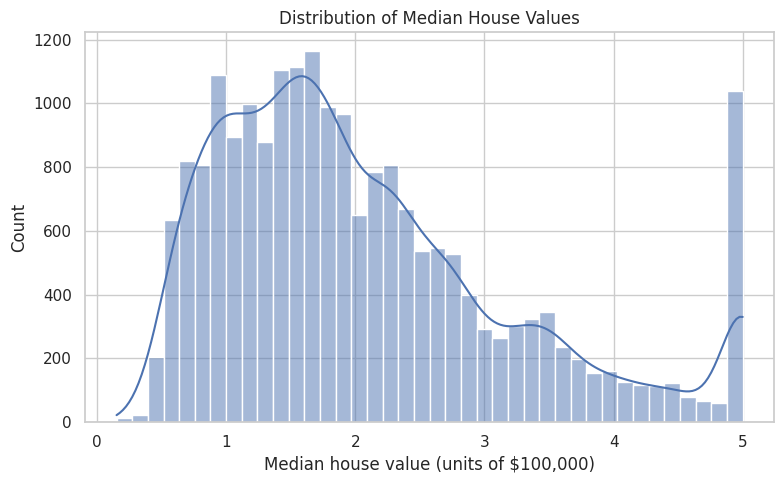

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(df["MedHouseVal"], bins=40, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median house value (units of $100,000)")
plt.tight_layout()
plt.show()

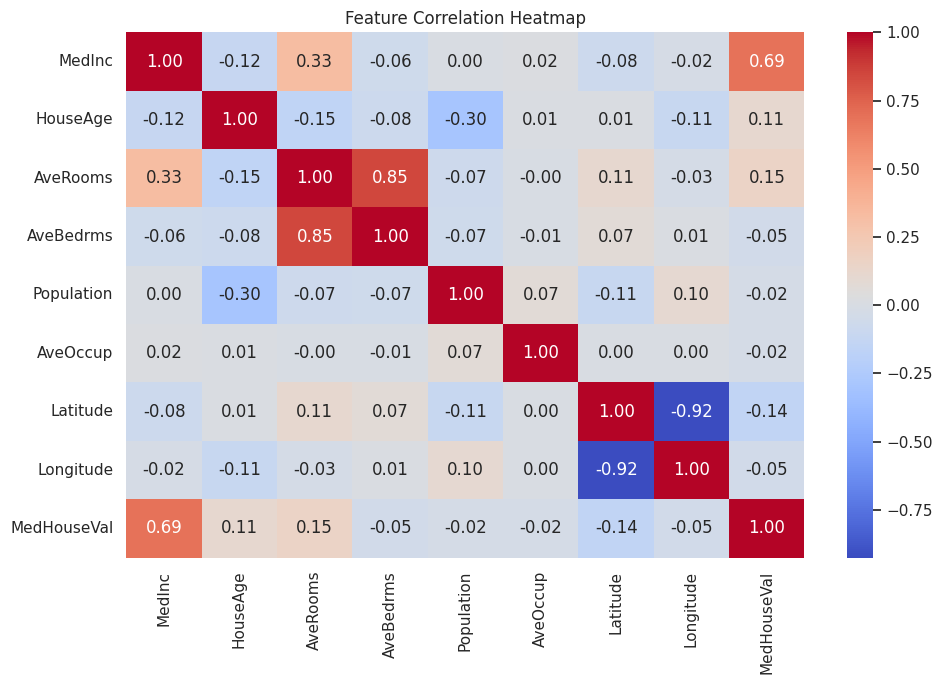

In [6]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

**EDA notes:** Use the histogram to describe the target distribution and the heatmap to identify features with stronger positive or negative linear associations with `MedHouseVal`. Correlation does not prove causation.

## 4. Select features and target

In [7]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]
print("Features:", X.shape)
print("Target:", y.shape)

Features: (20640, 8)
Target: (20640,)


## 5. Train/test split (80% / 20%)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 16512
Testing rows: 4128


## 6. Train Linear Regression

In [9]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Model trained successfully.")
print("Intercept:", model.intercept_)

Model trained successfully.
Intercept: -37.02327770606409


## 7. Make predictions

In [10]:
y_pred = model.predict(X_test)
display(pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": y_pred[:10]
}))

,Actual,Predicted
0,0.47700,0.719123
1,0.45800,1.764017
2,5.00001,2.709659
3,2.18600,2.838926
4,2.78000,2.604657
5,1.58700,2.011754
6,1.98200,2.645500
7,1.57500,2.168755
8,3.40000,2.740746
9,4.46600,3.915615


## 8. Evaluate model

In [11]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")
print(f"MAE in dollars: ${mae * 100000:,.2f}")
print(f"RMSE in dollars: ${rmse * 100000:,.2f}")

MAE:  0.5332
RMSE: 0.7456
R²:   0.5758
MAE in dollars: $53,320.01
RMSE in dollars: $74,558.14


**Metric meanings**
- **MAE:** Average absolute prediction error; lower is better.
- **RMSE:** Gives larger errors more weight; lower is better.
- **R²:** Proportion of target variation explained on the test data; closer to 1 is generally better, though it can be negative.

MAE and RMSE are in units of $100,000 because that is the scale of `MedHouseVal`.

## 9. Actual vs. predicted plot

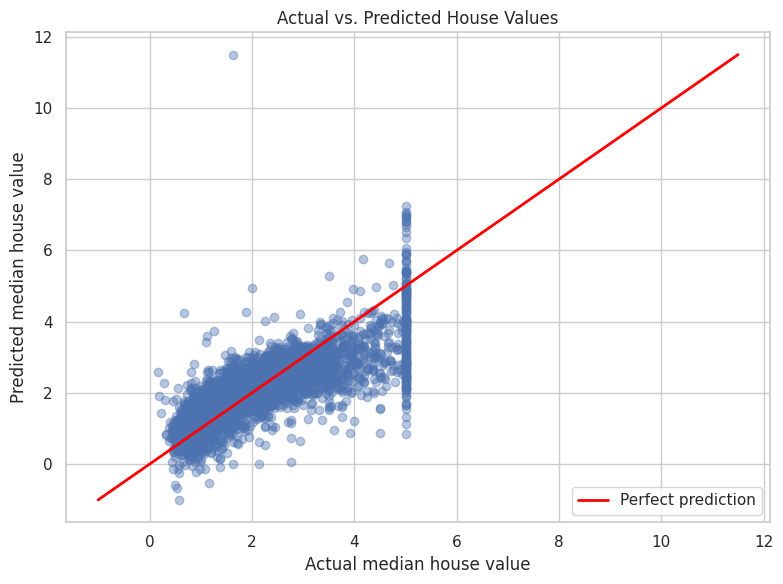

In [12]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], color="red", linewidth=2, label="Perfect prediction")
plt.xlabel("Actual median house value")
plt.ylabel("Predicted median house value")
plt.title("Actual vs. Predicted House Values")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Residual analysis

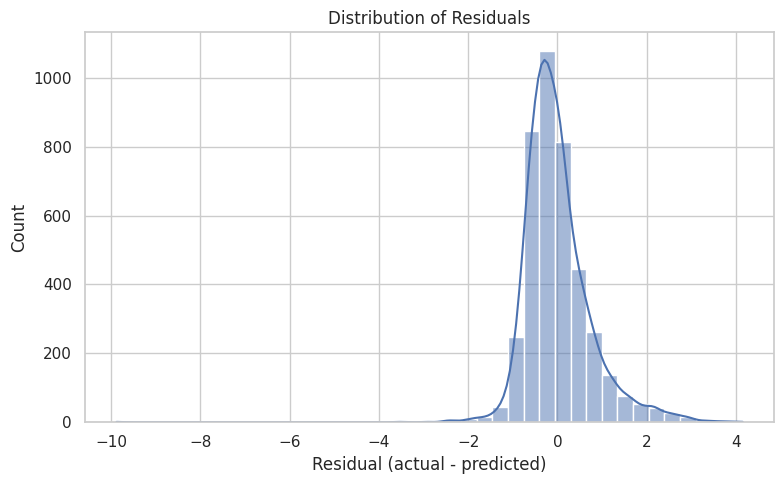

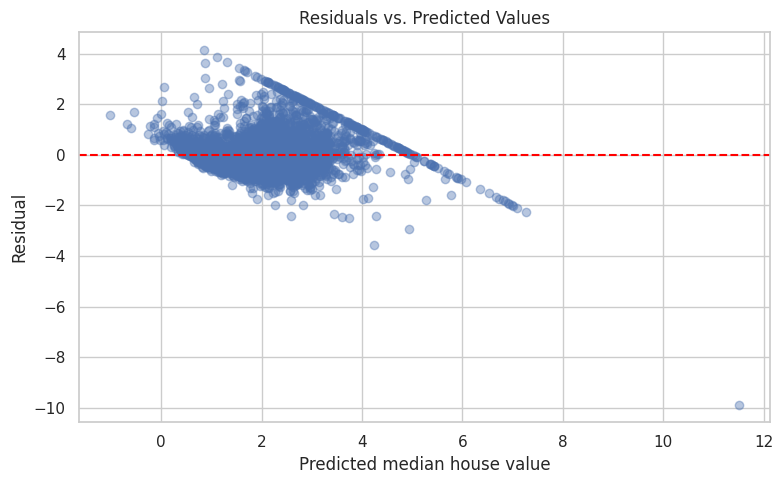

In [13]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=40, kde=True)
plt.title("Distribution of Residuals")
plt.xlabel("Residual (actual - predicted)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted median house value")
plt.ylabel("Residual")
plt.title("Residuals vs. Predicted Values")
plt.tight_layout()
plt.show()

## 11. Inspect feature coefficients

In [14]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
}).sort_values("Coefficient", key=abs, ascending=False)
display(coefficients)

,Feature,Coefficient
3,AveBedrms,0.783145
0,MedInc,0.448675
7,Longitude,-0.433708
6,Latitude,-0.419792
2,AveRooms,-0.123323
1,HouseAge,0.009724
5,AveOccup,-0.003526
4,Population,-0.000002


## 12. Save trained model

In [15]:
joblib.dump(model, "house_price_model.pkl")
print("Saved as house_price_model.pkl")

Saved as house_price_model.pkl


## 13. Predict for a new example

In [16]:
new_house = pd.DataFrame([{
    "MedInc": 5.0,
    "HouseAge": 20.0,
    "AveRooms": 6.0,
    "AveBedrms": 1.2,
    "Population": 1000.0,
    "AveOccup": 3.0,
    "Latitude": 34.05,
    "Longitude": -118.25
}])

predicted_value = model.predict(new_house)[0]
print(f"Predicted median house value: ${predicted_value * 100000:,.2f}")

Predicted median house value: $259,385.18


## 14. Conclusion and improvement ideas
A Linear Regression model was trained using the California Housing dataset and evaluated on unseen test data. Use the printed MAE, RMSE and R² values and the plots to describe its performance.

**Possible improvements**
1. Compare with Decision Tree and Random Forest regression.
2. Use cross-validation for a more robust performance estimate.
3. Try feature engineering and justified transformations.
4. Investigate outliers and residual patterns.
5. Use newer, relevant data before any real-world application.

**Limitation:** This historical, district-level dataset is for learning. It should not be used to value current individual properties or make financial decisions.